In [36]:
#1a set up choosing 70% of data
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("Frogs_MFCCs.csv")
print(df.shape)
df.head() 

X = df.drop(columns = ["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]
print("Features:", X.shape)
print("Labels:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("\nTraining set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

(7195, 26)
Features: (7195, 22)
Labels: (7195, 3)

Training set: (5036, 22)
Test set: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)


In [46]:
#1b three labels
#1bi exact match + hamming score
from sklearn.metrics import accuracy_score, hamming_loss
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV

# eval func for multi-label classification
def evaluate_model(y_true, y_pred):
    exact_match = np.mean(np.all(y_true.values == y_pred.values, axis=1))
    h_loss = np.mean(y_true.values != y_pred.values)
    h_score = 1 - h_loss
    return exact_match, h_score, h_loss

In [38]:
#1bii train a SVM for each label 
# define param values for CV
param_grid = {
    'estimator__C': [0.1, 1, 10, 100],
    'estimator__gamma': [0.01, 0.1, 1, 10]
}

# Gaussian kernel SVM with one-vs-rest classification
svm = OneVsRestClassifier(SVC(kernel='rbf'))

# 10-fold cross-validation
grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',
    n_jobs=-1 )


# training SVM for Family classification
grid_search.fit(X_train, y_train['Family'])

# best hyperparameters
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

#  Family labels (test s.)
family_pred = grid_search.predict(X_test)
family_accuracy = accuracy_score(y_test['Family'], family_pred)
print("Family Test Accuracy:", family_accuracy)


# SVM for Genus 
genus_grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)
genus_grid.fit(X_train, y_train['Genus'])
print("\nBest genus parameters:", genus_grid.best_params_)
print("Best genus CV accuracy:", genus_grid.best_score_)

genus_pred = genus_grid.predict(X_test)
genus_accuracy = accuracy_score(y_test['Genus'], genus_pred)
print("Genus Test Accuracy:", genus_accuracy)


# SVM for species 
species_grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

species_grid.fit(X_train, y_train['Species'])
print("\nBest species parameters:", species_grid.best_params_)
print("Best species CV accuracy:", species_grid.best_score_)
species_pred = species_grid.predict(X_test)
species_accuracy = accuracy_score(y_test['Species'], species_pred)
print("Species Test Accuracy:", species_accuracy)

#all three put together
y_pred = pd.DataFrame({
    'Family': family_pred,
    'Genus': genus_pred,
    'Species': species_pred
}, index=y_test.index)

def evaluate_model(y_true, y_pred):
    exact_match = np.mean(np.all(y_true.values == y_pred.values, axis=1))
    h_loss = np.mean(y_true.values != y_pred.values) # hamming loss: proportion of incorrect labels
    h_score = 1 - h_loss     # hamming score: proportion of correct labels
    return exact_match, h_score, h_loss

exact_match, h_score, h_loss = evaluate_model(y_test, y_pred)
# Display results
print("Exact Match:", exact_match)
print("Hamming Score:", h_score)
print("Hamming Loss:", h_loss)




Best parameters: {'estimator__C': 100, 'estimator__gamma': 1}
Best CV accuracy: 0.9920575751838177
Family Test Accuracy: 0.9958314034275128

Best genus parameters: {'estimator__C': 10, 'estimator__gamma': 1}
Best genus CV accuracy: 0.990070292530531
Genus Test Accuracy: 0.9902732746641963

Best species parameters: {'estimator__C': 10, 'estimator__gamma': 1}
Best species CV accuracy: 0.9898706964561835
Species Test Accuracy: 0.9907364520611394
Exact Match: 0.9874942102825383
Hamming Score: 0.9922803767176162
Hamming Loss: 0.0077196232823838196


In [ ]:
#1biii repeating 1bii with L1 penalized SVMs
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# L1-penalized SVM +  STANDARDIZED features
l1_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', OneVsRestClassifier(
        LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=20000,
            tol=1e-3,
            random_state=42
        )
    ))
])

# Penalty param vals
l1_param_grid = {'classifier__estimator__C': [0.01, 0.1, 1, 10, 100] }

l1_results = {}
l1_predictions = pd.DataFrame(index=y_test.index)

for label in ['Family', 'Genus', 'Species']:
    # 10-fold cross-validation
    l1_grid = GridSearchCV(
        estimator=l1_svm,
        param_grid=l1_param_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=-1
    )

    # training classifier
    l1_grid.fit(X_train, y_train[label])

    # predicting test labels
    pred = l1_grid.predict(X_test)
    l1_predictions[label] = pred

    l1_results[label] = {
        'Best C': l1_grid.best_params_['classifier__estimator__C'],
        'CV Accuracy': l1_grid.best_score_,
        'Test Accuracy': accuracy_score(y_test[label], pred)
    }
    print(f"\n{label}")
    print("Best C:", l1_results[label]['Best C'])
    print("Best CV Accuracy:", l1_results[label]['CV Accuracy'])
    print("Test Accuracy:", l1_results[label]['Test Accuracy'])


# L1-penalized SVM
l1_exact, l1_score, l1_loss = evaluate_model(y_test, l1_predictions)
print("L1 Exact Match:", l1_exact)
print("L1 Hamming Score:", l1_score)
print("L1 Hamming Loss:", l1_loss)


Family
Best C: 1
Best CV Accuracy: 0.9406288459717882
Test Accuracy: 0.9286706808707735


/Users/laurenjang/miniforge3/envs/dsci552/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Genus
Best C: 10
Best CV Accuracy: 0.9527422764997319
Test Accuracy: 0.9416396479851783


/Users/laurenjang/miniforge3/envs/dsci552/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Species
Best C: 10
Best CV Accuracy: 0.9602847202499291
Test Accuracy: 0.9592403890690134
L1 Exact Match: 0.9129226493747105
L1 Hamming Score: 0.9431835726416551
L1 Hamming Loss: 0.05681642735834491


In [40]:
#1biv repeat 1biii using SMOTE
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

smote_l1_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=1)),
    ('classifier', OneVsRestClassifier(
        LinearSVC(
            penalty='l1',
            dual=False,
            max_iter=20000,
            tol=1e-3,
            random_state=42
        )
    ))
])

# param values for 10-fold CV
smote_param_grid = {
    'classifier__estimator__C': [0.01, 0.1, 1, 10, 100]}

# results and predictions
smote_results = {}
smote_predictions = pd.DataFrame(index=y_test.index)

# separate classifiers for each label
for label in ['Family', 'Genus', 'Species']:

    # 10-fold cross-validation
    smote_grid = GridSearchCV(
        estimator=smote_l1_svm,
        param_grid=smote_param_grid,
        cv=10,
        scoring='accuracy',
        n_jobs=2
    )

    #classifier
    smote_grid.fit(X_train, y_train[label])

    # test labels
    pred = smote_grid.predict(X_test)
    smote_predictions[label] = pred

    smote_results[label] = {
        'Best C': smote_grid.best_params_['classifier__estimator__C'],
        'CV Accuracy': smote_grid.best_score_,
        'Test Accuracy': accuracy_score(y_test[label], pred)
    }

    print(f"\n{label}")
    print("Best C:", smote_results[label]['Best C'])
    print("Best CV Accuracy:", smote_results[label]['CV Accuracy'])
    print("Test Accuracy:", smote_results[label]['Test Accuracy'])


# all three labels together
def evaluate_model(y_true, y_pred):
    exact_match = np.mean(
        np.all(y_true.values == y_pred.values, axis=1)
    )
    h_loss = np.mean(y_true.values != y_pred.values)
    h_score = 1 - h_loss

    return exact_match, h_score, h_loss


smote_exact, smote_score, smote_loss = evaluate_model(
    y_test, smote_predictions
)

print("\nSMOTE L1 SVM Results")
print("Exact Match:", smote_exact)
print("Hamming Score:", smote_score)
print("Hamming Loss:", smote_loss)



Family
Best C: 1
Best CV Accuracy: 0.9187892486351732
Test Accuracy: 0.9082908754052802

Genus
Best C: 10
Best CV Accuracy: 0.9106452554514185
Test Accuracy: 0.9004168596572487

Species
Best C: 1
Best CV Accuracy: 0.9545256240335764
Test Accuracy: 0.953682260305697

SMOTE L1 SVM Results
Exact Match: 0.8503937007874016
Hamming Score: 0.920796665122742
Hamming Loss: 0.07920333487725799


QUESTION 1B interpretation iv 

The Gaussian RBF SVM had the highest exact match and the hamming score, in addition to having the lowest hamming loss. The initial L1-penalized support vector machine performed worse than the Gaussian support vector machine, but still performed better than the L1 support vector machine with SMOTE. After SMOTE, the exact match decreased from 91.29 to 85.04, while the Hamming loss increased from 5.68 to 7.92. This implies that SMOTE did not improve the overall classification accuracy, but might have improved the classification minority classes, which would require additional class-level evaluation to confirm. 


In [41]:
#2 K-Means Clustering on a Multi-Class and Multi-Label Data Set
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Use the entire dataset
X_cluster = df.drop(columns=[
    'Family', 'Genus', 'Species', 'RecordID'])

y_cluster = df[['Family', 'Genus', 'Species']].reset_index(drop=True)

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

def find_best_k(X, seed):
    silhouette_scores = []

    for k in range(2, 51):
        kmeans = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10  )

        cluster_labels = kmeans.fit_predict(X)

        score = silhouette_score(
            X,
            cluster_labels,
            sample_size=2000,
            random_state=seed )

        silhouette_scores.append(score)
    best_k = np.argmax(silhouette_scores) + 2
    return best_k

print("Feature shape:", X_cluster_scaled.shape)
print("Label shape:", y_cluster.shape)

best_k = find_best_k(X_cluster_scaled, 42)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10)

cluster_labels = kmeans.fit_predict(X_cluster_scaled)
print("Optimal number of clusters:", best_k)

Feature shape: (7195, 22)
Label shape: (7195, 3)
Optimal number of clusters: 5


In [42]:
#2b determine which family is the majority by reading the true labels
cluster_df = y_cluster.copy()
cluster_df['Cluster'] = cluster_labels

# majority labels
majority_labels = cluster_df.groupby('Cluster')[ 
    ['Family', 'Genus', 'Species']
].agg(lambda x: x.value_counts().idxmax())
print("Majority labels for each cluster:")
print(majority_labels)

#majority to each observation
cluster_predictions = majority_labels.loc[
    cluster_labels, ['Family', 'Genus', 'Species']
].reset_index(drop=True)

incorrect = y_cluster.values != cluster_predictions.values

hamming_distance = np.mean(np.sum(incorrect, axis=1))
hamming_loss = np.mean(incorrect)
hamming_score = 1 - hamming_loss

print("\nHamming Distance:", hamming_distance)
print("Hamming Score:", hamming_score)
print("Hamming Loss:", hamming_loss)

Majority labels for each cluster:
                  Family      Genus                 Species
Cluster                                                    
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1                Hylidae  Hypsiboas    HypsiboasCinerascens
2        Leptodactylidae  Adenomera          AdenomeraAndre
3        Leptodactylidae  Adenomera          AdenomeraAndre
4                Hylidae  Hypsiboas       HypsiboasCordobae

Hamming Distance: 0.590271021542738
Hamming Score: 0.8032429928190874
Hamming Loss: 0.19675700718091266


In [43]:
#2c for each cluster, calculate avg Hamming distance,s score, and loss
hamming_distances = []
hamming_scores = []
hamming_losses = []
optimal_k_values = []

for i in range(50):

    # optimal k
    best_k = find_best_k(X_cluster_scaled, i)
    optimal_k_values.append(best_k)

    # K-Means
    kmeans = KMeans(
        n_clusters=best_k,
        random_state=i,
        n_init=10 )

    cluster_labels = kmeans.fit_predict(X_cluster_scaled)

    # majority label from 2b
    cluster_df = y_cluster.copy()
    cluster_df['Cluster'] = cluster_labels
    majority_labels = cluster_df.groupby('Cluster')[
        ['Family', 'Genus', 'Species']
    ].agg(lambda x: x.value_counts().idxmax())

    # majority labels to obs
    predictions = majority_labels.loc[
        cluster_labels, ['Family', 'Genus', 'Species']
    ].reset_index(drop=True)

    # Hamming metrics
    incorrect = y_cluster.values != predictions.values
    distance = np.mean(np.sum(incorrect, axis=1))
    loss = np.mean(incorrect)
    score = 1 - loss

    hamming_distances.append(distance)
    hamming_scores.append(score)
    hamming_losses.append(loss)
    print(f"Run {i+1}/50: k={best_k}, Distance={distance:.4f}")

# Monte Carlo 
print("\nMonte Carlo Results")
print("Mean Hamming Distance:", np.mean(hamming_distances))
print("Standard Deviation:", np.std(hamming_distances))
print("Mean Hamming Score:", np.mean(hamming_scores))
print("Mean Hamming Loss:", np.mean(hamming_losses))
print("Optimal k values:", optimal_k_values)

Run 1/50: k=3, Distance=0.8460
Run 2/50: k=3, Distance=0.8460
Run 3/50: k=3, Distance=0.8460
Run 4/50: k=3, Distance=0.8460
Run 5/50: k=5, Distance=0.5903
Run 6/50: k=3, Distance=0.8460
Run 7/50: k=3, Distance=0.8460
Run 8/50: k=5, Distance=0.5903
Run 9/50: k=4, Distance=0.6978
Run 10/50: k=3, Distance=0.8460
Run 11/50: k=4, Distance=0.6978
Run 12/50: k=3, Distance=0.8460
Run 13/50: k=3, Distance=0.8460
Run 14/50: k=3, Distance=0.8460
Run 15/50: k=3, Distance=0.8460
Run 16/50: k=4, Distance=0.7423
Run 17/50: k=3, Distance=0.8460
Run 18/50: k=3, Distance=0.8460
Run 19/50: k=3, Distance=0.8460
Run 20/50: k=3, Distance=0.8460
Run 21/50: k=3, Distance=0.8460
Run 22/50: k=3, Distance=0.8460
Run 23/50: k=4, Distance=0.6966
Run 24/50: k=3, Distance=0.8460
Run 25/50: k=3, Distance=0.8460
Run 26/50: k=6, Distance=0.5858
Run 27/50: k=5, Distance=0.5903
Run 28/50: k=3, Distance=0.8460
Run 29/50: k=5, Distance=0.5903
Run 30/50: k=3, Distance=0.8460
Run 31/50: k=3, Distance=0.8460
Run 32/50: k=3, D

# QUESTION 2
The K-means clustering produced a mean hamming distance of 0.7822 and a standard deviation of 0.0986. The mean hamming score was 0.7393, while the hamming mean loss was 0.2607. The optimal number of clusters varied, but k=3 was selected the most commonly. The conclusions suggest that the clustering performance is relatively sensitive to the number of clusters used. 

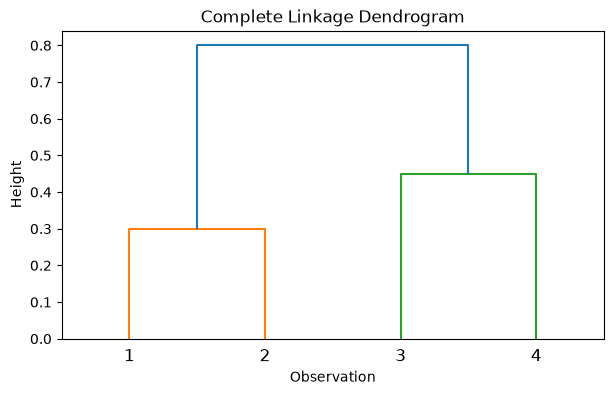

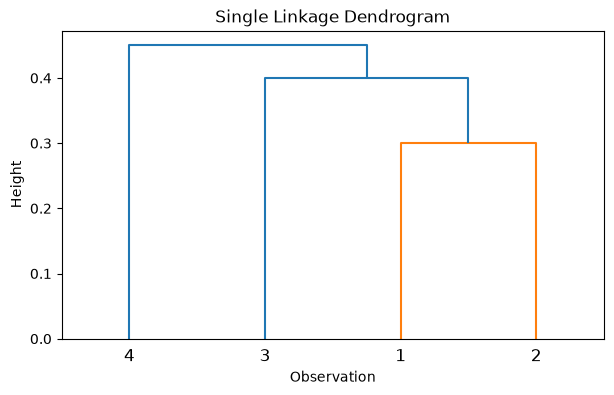

In [44]:
#3 ISLR 12.6.2
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

distances = [0.3, 0.4, 0.7, 0.5, 0.8, 0.45] #matrix 
complete = linkage(distances, method='complete')

plt.figure(figsize=(7, 4))
dendrogram(complete, labels=['1', '2', '3', '4'])
plt.title('Complete Linkage Dendrogram')
plt.xlabel('Observation')
plt.ylabel('Height')
plt.show()


#3b single linkage dendrogram
single = linkage(distances, method='single')
plt.figure(figsize=(7, 4))
dendrogram(
    single,
    labels=['1', '2', '3', '4'])

plt.title('Single Linkage Dendrogram')
plt.xlabel('Observation')
plt.ylabel('Height')
plt.show()



QUESTION 3C 
Cluster 1: 2, cluster 2: 4

QUESTION 3D
Cluster 1: 3, cluster 2: 4.

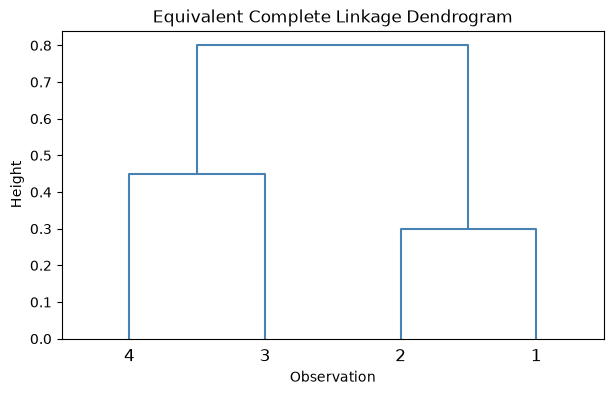

In [45]:
#3e equivalent to dendrogram in (a) 
from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
dendrogram(
    complete,
    labels=['1', '2', '3', '4'],
    leaf_rotation=0,
    link_color_func=lambda k: 'steelblue',
    count_sort='descending')

plt.title('Equivalent Complete Linkage Dendrogram')
plt.xlabel('Observation')
plt.ylabel('Height')
plt.show()

#3e 

My code utilizes count_sort='descending', which changes the order of branches. The dendrogram is equivalent to the dendrogram in part (a), while the positions of each observations are swapped. The same observations merge at heights of 0.3 and 0.45, then the two clusters merge at height 0.80. So, though there are different leaf positions the clustering structure is unchanged. 